# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [33]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [34]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [35]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [36]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)

def generate(tag):
    n = random.randint(1, 100)
    lst = list(numbers)          # копія: старт завжди однаковий
    random.shuffle(lst)
    print(f"{tag}: randint = {n:3d} | shuffle = {lst}")

print("--- ДО set_seed() ---")
generate("спроба 1")
generate("спроба 2")

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ окремим генеруванням

print("\n--- set_seed() ПЕРЕД КОЖНОЮ генерацією ---")
set_seed(); generate("спроба 3")
set_seed(); generate("спроба 4")

# TODO: тепер ще двічі без проміжних викликів set_seed()

print("\n--- ті самі виклики, але БЕЗ проміжного set_seed() ---")
generate("спроба 5")
generate("спроба 6")

--- ДО set_seed() ---
спроба 1: randint =   4 | shuffle = [7, 6, 2, 9, 0, 5, 1, 8, 3, 4]
спроба 2: randint =   5 | shuffle = [6, 7, 2, 9, 5, 4, 8, 3, 1, 0]
Seed зафіксовано: 42

--- set_seed() ПЕРЕД КОЖНОЮ генерацією ---
спроба 3: randint =  82 | shuffle = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
спроба 4: randint =  82 | shuffle = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

--- ті самі виклики, але БЕЗ проміжного set_seed() ---
спроба 5: randint =  76 | shuffle = [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
спроба 6: randint =  92 | shuffle = [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


**Що відбувається.** `random` — це не справжня випадковість, а детермінований
генератор псевдовипадкових чисел. У нього є внутрішній стан, і кожен виклик
`randint`/`shuffle` бере наступне число з послідовності та зсуває цей стан далі.

`set_seed(42)` повертає стан у фіксовану стартову точку. Тому:

- **спроби 1 і 2 (до seed)** — стан невідомий і рухається далі, результати різні;
- **спроби 3 і 4** — перед кожною з них стан скинуто в ту саму точку, тому
  обидві дали `randint = 82` і ту саму перестановку. Це відтворюваність:
  запустивши ноутбук завтра, я отримаю ті самі числа;
- **спроби 5 і 6** — seed не скидався, генератор просто продовжив послідовність
  з того місця, де зупинився, тому числа знову різні.

Висновок: seed фіксує **всю послідовність від точки скидання**, а не окремий
виклик. Тому в ML `set_seed()` викликають один раз на початку експерименту —
щоб увесь прогін (генерація даних, перемішування, ініціалізація ваг) був
відтворюваним цілком.

Окремо: у `generate()` список для shuffle щоразу створюється заново копією
(`list(numbers)`). Якби я перемішувала один і той самий список, спроби 3 і 4
стартували б з різних порядків і не збіглися б — і демонстрація зламалась би.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [37]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [38]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [39]:
# TODO: zeros_arr = np.zeros((3, 4))
# TODO: sevens_arr = np.full((3, 4), 7)
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [40]:
# TODO: arange_arr = np.arange(0, 20, 2)
# TODO: linspace_arr = np.linspace(0, 1, 5)
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [41]:
# TODO: identity = np.eye(4)
# TODO: random_ints = np.random.randint(0, 10, size=(3, 3))
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print("ndim:", identity.ndim, random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
ndim: 2 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [42]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [43]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [44]:
df = pd.DataFrame({
    "name":  ["Анна", "Іван", "Вікторія", "Денис", "Олена", "Максим"],
    "group": ["ІПЗ-23-3"] * 6,
    "score": [92, 78, 85, 64, 95, 81],
}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням

top = df[df["score"] > 80].sort_values("score", ascending=False)
print(top)


       name     group  score
4     Олена  ІПЗ-23-3     95
0      Анна  ІПЗ-23-3     92
2  Вікторія  ІПЗ-23-3     85
5    Максим  ІПЗ-23-3     81


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [45]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.where(df["score"] >= 90, "A",
              np.where(df["score"] >= 75, "B", "C"))
print(df)


       name     group  score grade
0      Анна  ІПЗ-23-3     92     A
1      Іван  ІПЗ-23-3     78     B
2  Вікторія  ІПЗ-23-3     85     B
3     Денис  ІПЗ-23-3     64     C
4     Олена  ІПЗ-23-3     95     A
5    Максим  ІПЗ-23-3     81     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [46]:
# TODO: zeros_t = torch.zeros((2, 3))
# TODO: sevens_t = torch.full((2, 3), 7)
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [47]:
# TODO: arange_t = torch.arange(0, 20, 2)
# TODO: linspace_t = torch.linspace(0, 1, 5)
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [48]:
# TODO: from_list = torch.tensor([[1, 2], [3, 4]])
# TODO: random_t = torch.rand(3, 3)
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)


tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [49]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("autograd dy/dx =", x.grad.item())
print("аналітично 2x  =", 2 * n)

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n


autograd dy/dx = 10.0
аналітично 2x  = 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [50]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

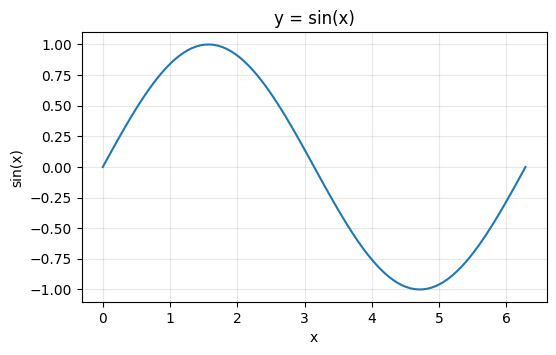

In [51]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()

xs = np.linspace(0, 2 * np.pi, 100)

plt.figure(figsize=(6, 3.5))
plt.plot(xs, np.sin(xs))
plt.title("y = sin(x)")
plt.xlabel("x"); plt.ylabel("sin(x)")
plt.grid(alpha=0.3)
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

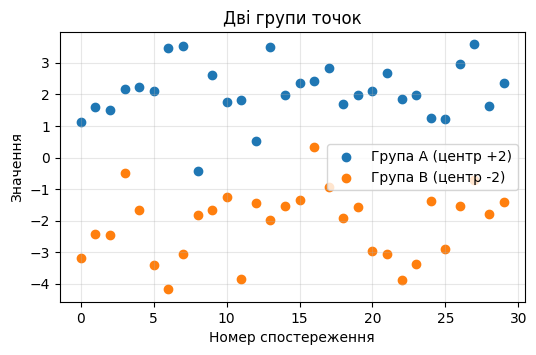

In [52]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.figure(figsize=(6, 3.5))
plt.scatter(np.arange(30), group_a, color="C0", label="Група A (центр +2)")
plt.scatter(np.arange(30), group_b, color="C1", label="Група B (центр -2)")
plt.xlabel("Номер спостереження"); plt.ylabel("Значення")
plt.title("Дві групи точок")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [53]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

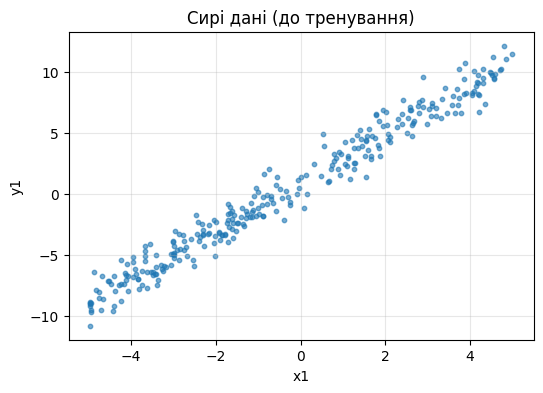

In [54]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"

plt.figure(figsize=(6, 4))
plt.scatter(x1.numpy(), y1.numpy(), s=10, alpha=0.6)
plt.xlabel("x1"); plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(alpha=0.3)
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [55]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

set_seed()
perm = torch.randperm(TASK1_N)
x1_sh, y1_sh = x1[perm], y1[perm]

n_train = int(0.70 * TASK1_N)
n_val   = int(0.15 * TASK1_N)

x_train1, y_train1 = x1_sh[:n_train], y1_sh[:n_train]
x_val1,   y_val1   = x1_sh[n_train:n_train + n_val], y1_sh[n_train:n_train + n_val]
x_test1,  y_test1  = x1_sh[n_train + n_val:], y1_sh[n_train + n_val:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [56]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=43.316730  w=1.5235 (true 2.0)  b=0.0181 (true 1.0)
epoch   30  loss=1.000557  w=1.9719 (true 2.0)  b=0.9505 (true 1.0)
epoch   60  loss=0.997888  w=1.9749 (true 2.0)  b=0.9956 (true 1.0)
epoch   90  loss=0.997882  w=1.9750 (true 2.0)  b=0.9978 (true 1.0)
epoch   99  loss=0.997882  w=1.9750 (true 2.0)  b=0.9978 (true 1.0)


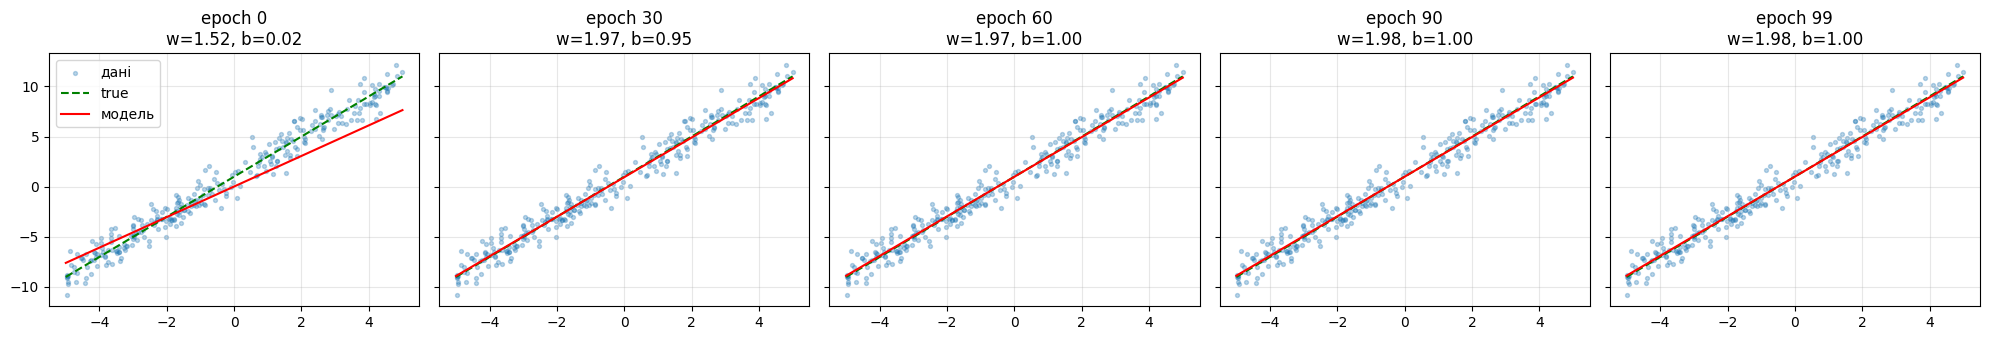

In [57]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

**Виконання вправи 20.** Власний сценарій: практика англійської → бал за тест

**Залежність:** `бал = 4.5 · (годин практики на тиждень) + 45 + шум`

**Чому саме такі параметри:**

- **b = 45.** Це "стартовий" бал людини, яка цього тижня не практикувалася
  взагалі. Вона не повний нуль — у неї є база зі школи, тому нуль годин
  не означає нуль балів. 45 зі 100 — приблизно рівень "щось пам'ятаю".
- **w = 4.5.** Кожна додаткова година практики додає ~4.5 бала. При
  10 годинах на тиждень виходить 45 + 45 = 90 балів, що виглядає
  правдоподібно як стеля для реалістичного навантаження.
- **Шум σ = 5.** Бал залежить не лише від годин: настрій, складність
  конкретного варіанту, сон. +-5 балів розкиду — помірна, не абсурдна
  варіація.
- **Діапазон x: 0–14 годин.** Це 0–2 години на день — реальний діапазон
  для студента, який вчить мову паралельно з навчанням.

**Обмеження моделі:** залежність лінійна на всьому проміжку, тобто модель
вважає, що 50 годин практики дадуть 270 балів. У реальності є стеля
(100 балів) і спад віддачі. Для цих даних лінійна модель адекватна лише
всередині діапазону 0–14, за його межами екстраполяція буде хибною.

In [58]:
# ---------- 1. Генерація даних ----------
def make_linear_data(n, w, b, noise_std, x_min, x_max, seed=SEED):
    """y = w*x + b + N(0, noise_std). Повертає тензори (n, 1)."""
    set_seed(seed)
    x = torch.empty(n, 1).uniform_(x_min, x_max)
    y = w * x + b + noise_std * torch.randn(n, 1)
    return x, y


# ---------- 2. Розбиття на train/val/test ----------
def split_data(x, y, train_frac=0.70, val_frac=0.15, seed=SEED):
    """Перемішує і ріже на три частини. Повертає 3 пари (x, y)."""
    set_seed(seed)
    n = len(x)
    perm = torch.randperm(n)
    x, y = x[perm], y[perm]
    n_tr = int(train_frac * n)
    n_va = int(val_frac * n)
    return ((x[:n_tr],             y[:n_tr]),
            (x[n_tr:n_tr + n_va],  y[n_tr:n_tr + n_va]),
            (x[n_tr + n_va:],      y[n_tr + n_va:]))


# ---------- 3. Цикл навчання ----------
def train_model(model, train, val, epochs=2000, lr=0.01,
                loss_fn=None, log_every=250):
    """Тренує model на train, щоепохи міряє loss на val. Повертає історію."""
    x_tr, y_tr = train
    x_va, y_va = val
    loss_fn = loss_fn or torch.nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = {"train": [], "val": []}

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(x_tr), y_tr)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_va), y_va)

        history["train"].append(loss.item())
        history["val"].append(val_loss.item())

        if epoch % log_every == 0 or epoch == epochs - 1:
            print(f"epoch {epoch:5d}  train={loss.item():9.4f}  val={val_loss.item():9.4f}")

    return history


# ---------- 4. Оцінка на відкладеній вибірці ----------
def evaluate(model, data, loss_fn=None):
    x, y = data
    loss_fn = loss_fn or torch.nn.MSELoss()
    model.eval()
    with torch.no_grad():
        return loss_fn(model(x), y).item()


print("Функції готові")

Функції готові


Дані і збереження CSV:

CSV збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
   hours_practice  test_score
0       12.351769  100.706459
1       12.810056   97.324509
2        5.360093   65.319450
3       13.430279  103.398727
4        5.466275   74.410057
       hours_practice  test_score
count      400.000000  400.000000
mean         6.598939   74.742416
std          4.083967   18.782940
min          0.032839   36.888149
25%          2.986347   59.296705
50%          6.044412   74.699768
75%         10.188632   90.743883
max         13.997262  120.802109


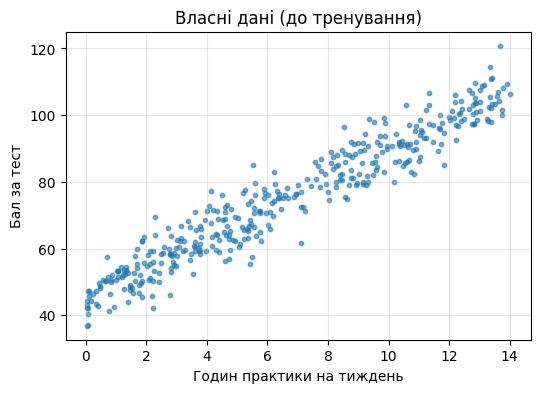

In [59]:
MY_W, MY_B, MY_NOISE, MY_N = 4.5, 45.0, 5.0, 400

x2, y2 = make_linear_data(MY_N, MY_W, MY_B, MY_NOISE, x_min=0.0, x_max=14.0)

df2 = pd.DataFrame({
    "hours_practice": x2.squeeze(1).numpy(),
    "test_score":     y2.squeeze(1).numpy(),
})

CSV_PATH = os.path.join(ARTIFACT_DIR, "dataset.csv")
df2.to_csv(CSV_PATH, index=False)
print("CSV збережено:", CSV_PATH)
print(df2.head())
print(df2.describe())

plt.figure(figsize=(6, 4))
plt.scatter(df2["hours_practice"], df2["test_score"], s=10, alpha=0.6)
plt.xlabel("Годин практики на тиждень"); plt.ylabel("Бал за тест")
plt.title("Власні дані (до тренування)")
plt.grid(alpha=0.3)
plt.show()

Тренування:

In [60]:
train2, val2, test2 = split_data(x2, y2)
print(f"train/val/test: {len(train2[0])}/{len(val2[0])}/{len(test2[0])}")

set_seed()
my_model = torch.nn.Linear(1, 1)
history = train_model(my_model, train2, val2, epochs=2000, lr=0.01)

test_mse = evaluate(my_model, test2)
print("\nTest MSE:", round(test_mse, 4))
print(f"Вивчене w = {my_model.weight.item():.4f}  (справжнє {MY_W})")
print(f"Вивчене b = {my_model.bias.item():.4f}  (справжнє {MY_B})")

train/val/test: 280/60/60
epoch     0  train=4932.5337  val= 537.0870
epoch   250  train=  55.7222  val=  46.5434
epoch   500  train=  28.6539  val=  26.6820
epoch   750  train=  27.3270  val=  25.6318
epoch  1000  train=  27.2620  val=  25.5633
epoch  1250  train=  27.2588  val=  25.5562
epoch  1500  train=  27.2586  val=  25.5551
epoch  1750  train=  27.2586  val=  25.5548
epoch  1999  train=  27.2586  val=  25.5548

Test MSE: 20.3903
Вивчене w = 4.4286  (справжнє 4.5)
Вивчене b = 45.4304  (справжнє 45.0)


Графіки:

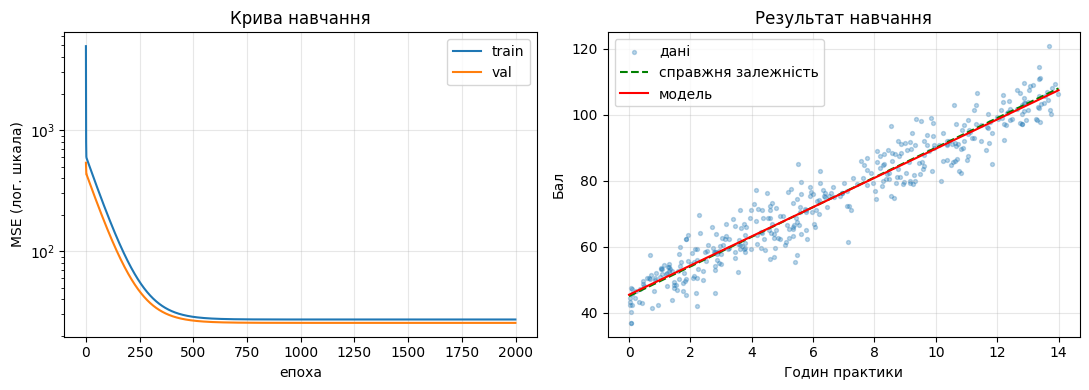

In [61]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.yscale("log")
plt.xlabel("епоха"); plt.ylabel("MSE (лог. шкала)")
plt.title("Крива навчання"); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
x_line2 = torch.linspace(0, 14, 100).unsqueeze(1)
with torch.no_grad():
    y_line2 = my_model(x_line2)
plt.scatter(x2.numpy(), y2.numpy(), s=8, alpha=0.3, label="дані")
plt.plot(x_line2.numpy(), (MY_W * x_line2 + MY_B).numpy(), "g--", label="справжня залежність")
plt.plot(x_line2.numpy(), y_line2.numpy(), "r-", label="модель")
plt.xlabel("Годин практики"); plt.ylabel("Бал")
plt.title("Результат навчання"); plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [62]:
MODEL_PATH = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(my_model.state_dict(), MODEL_PATH)
print("Модель збережено:", MODEL_PATH)

# Перевірка: вантажимо у свіжу модель і порівнюємо прогноз
check_model = torch.nn.Linear(1, 1)
check_model.load_state_dict(torch.load(MODEL_PATH))
check_model.eval()

with torch.no_grad():
    probe = torch.tensor([[7.0]])
    print("Прогноз оригіналу      :", round(my_model(probe).item(), 4))
    print("Прогноз завантаженої   :", round(check_model(probe).item(), 4))

print("\nФайли в ARTIFACT_DIR:", os.listdir(ARTIFACT_DIR))

Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt
Прогноз оригіналу      : 76.4307
Прогноз завантаженої   : 76.4307

Файли в ARTIFACT_DIR: ['runs', 'dataset.csv', 'model.pt']


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [63]:
!pip install -q gradio
import gradio as gr

In [64]:
import gradio as gr

# Вантажимо модель з Диска — комірка самодостатня, не залежить від тренування вище
app_model = torch.nn.Linear(1, 1)
app_model.load_state_dict(torch.load(os.path.join(ARTIFACT_DIR, "model.pt")))
app_model.eval()


def predict_score(hours):
    with torch.no_grad():
        score = app_model(torch.tensor([[float(hours)]])).item()
    score = max(0.0, min(100.0, score))   # бал не може вийти за 0..100
    return f"Прогнозований бал: {score:.1f} / 100"

demo = gr.Interface(
    fn=predict_score,
    inputs=gr.Slider(0, 14, value=7, step=0.5,
                     label="Годин практики англійської на тиждень"),
    outputs=gr.Textbox(label="Прогноз моделі"),
    title="Лабораторна 1 — лінійна регресія",
    description="Модель навчена на власному датасеті: y = 4.5·x + 45 + шум.",
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f676514afcf8c54e39.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```